In [3]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files = sorted(das_data.glob("train_*.h5"))

now :  train_1000.h5
now :  train_1001.h5
now :  train_1010.h5
now :  train_1011.h5
now :  train_1100.h5
now :  train_1101.h5
now :  train_1110.h5
now :  train_1111.h5
total values:  10737418240
values below range:  32296
values above range:  32040
fraction outside range:  5.991756916046143e-06


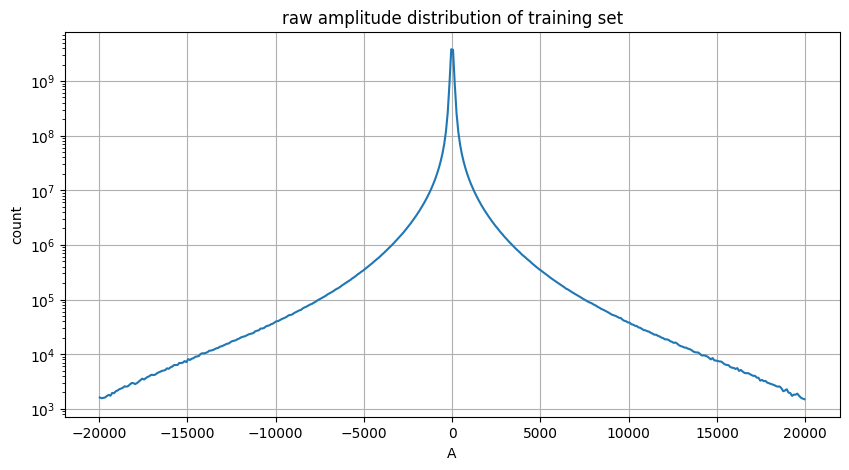

In [4]:
A_limit = 20000
num_intervals = 400
chunks = 64
edges = np.linspace(-A_limit, A_limit, num_intervals+1)
hist_counts = np.zeros(num_intervals, dtype= np.int64)
total_values = 0
below_range = 0
above_range = 0

for file in train_files:
    print("now : ", file.name)
    with h5py.File(file,"r") as f:
        patches=f["patches"]
        num_patches = patches.shape[0]
        for i in range (0, num_patches, chunks):
            end = min(i+chunks, num_patches)
            chunk = patches[i:end]
            total_values+= chunk.size
            below_range+= np.sum(chunk < -A_limit)
            above_range+= np.sum(chunk > A_limit)
            counts,_ = np.histogram(chunk, bins= edges)
            hist_counts += counts

print("total values: ", total_values)
print("values below range: ", below_range)
print("values above range: ", above_range)
print("fraction outside range: ", (below_range+above_range)/total_values)

intervals_centers = (edges[:-1] + edges[1:])/2
plt.figure(figsize=(10, 5))
plt.plot(intervals_centers, hist_counts)
plt.yscale("log")
plt.title("raw amplitude distribution of training set")
plt.xlabel("A")
plt.ylabel("count")
plt.grid(True)
plt.show()


In [6]:
abs_interval_centers = np.abs(intervals_centers)
order_mask = np.argsort(abs_interval_centers)
sorted_abs_values = abs_interval_centers[order_mask]
sorted_counts = hist_counts[order_mask]
cum_counts = np.cumsum(sorted_counts)
percentiles = [50, 90, 99, 99.9, 99.99, 99.999]
for p in percentiles:
    target = total_values*(p/100)
    index= np.searchsorted(cum_counts, target)
    value = sorted_abs_values[index]
    print(f"|x| percentile {p}% approx: {value}")

|x| percentile 50% approx: 50.0
|x| percentile 90% approx: 250.0
|x| percentile 99% approx: 1750.0
|x| percentile 99.9% approx: 5750.0
|x| percentile 99.99% approx: 12350.0
|x| percentile 99.999% approx: 18850.0


In [7]:
import json
output_path=Path("../outputs/DAS_data_analysis")
output_path.mkdir(parents= True, exist_ok=True)
save_path = output_path/"raw_amplitude_histogram_train.npz"
np.savez_compressed(save_path, bins=edges, hist_counts=hist_counts, 
                    total_values= np.array(total_values),
                    below_range= np.array(below_range),
                    above_range= np.array(above_range),
                    amplitude_limit=np.array(A_limit),
                    num_bins=np.array(num_intervals))
print("saved to: ", save_path)

saved to:  ../outputs/DAS_data_analysis/raw_amplitude_histogram_train.npz


In [21]:
import sys
sys.path.append("..")
from utils.normalizer import normalize, denormalize, get_config
print(get_config())

{'type': 'arcsinh', 's': 50.0, 'A_max': 12350.0}


In [12]:
import torch
file = das_data/"train_1111.h5"
i=0

with h5py.File(file,"r") as f:
    patch = torch.tensor(f["patches"][i])

patch_normalized= normalize(patch)
patch_denormalized = denormalize(patch_normalized)
print("min/max: ", patch.min().item(), patch.max().item())
print("normalized min/max: ", patch_normalized.min().item(), patch_normalized.max().item())
print("denormalized min/max: ", patch_denormalized.min().item(), patch_denormalized.max().item())
error=torch.max(torch.abs(patch-patch_denormalized))
print("max denormalization error: ", error.item())

min/max:  -3518.070556640625 3254.90283203125
normalized min/max:  -0.797551155090332 0.7850172519683838
denormalized min/max:  -3518.070556640625 3254.90185546875
max denormalization error:  0.0009765625


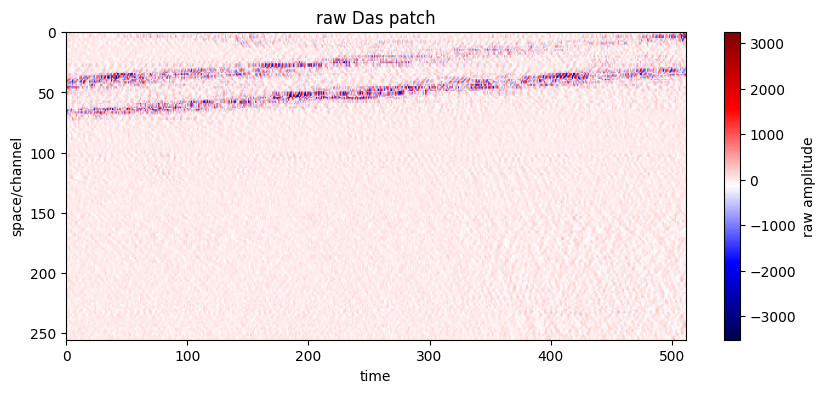

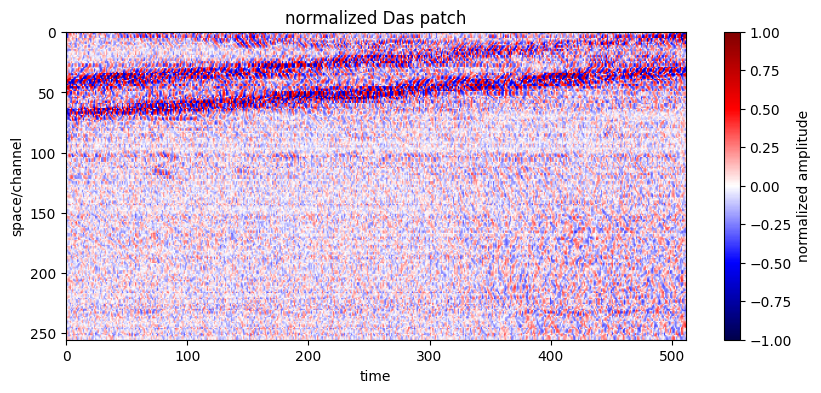

In [13]:
plt.figure(figsize=(10,4))
plt.imshow(patch.numpy(), aspect="auto", cmap="seismic")
plt.colorbar(label="raw amplitude")
plt.title("raw Das patch")
plt.xlabel("time")
plt.ylabel("space/channel")
plt.show()

plt.figure(figsize=(10,4))
plt.imshow(patch_normalized.numpy(), aspect="auto", cmap="seismic", vmin=-1, vmax=1)
plt.colorbar(label="normalized amplitude")
plt.title("normalized Das patch")
plt.xlabel("time")
plt.ylabel("space/channel")
plt.show()

In [18]:
loading_path = "../outputs/DAS_data_analysis/raw_amplitude_histogram_train.npz"
data = np.load(loading_path)
edges = data["bins"]
hist_counts=data["hist_counts"]
intervals_centers = torch.tensor((edges[:-1] + edges[1:])/2)
normalized_centers = normalize(intervals_centers).numpy()

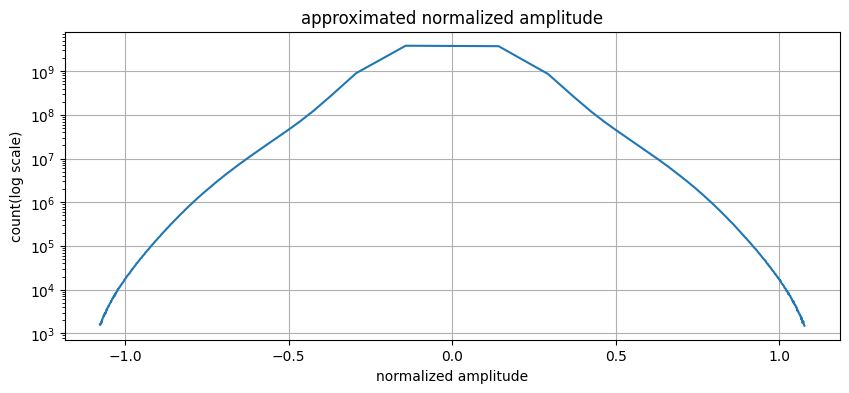

In [19]:
plt.figure(figsize=(10,4))
plt.plot(normalized_centers, hist_counts)
plt.yscale("log")
plt.title("approximated normalized amplitude")
plt.xlabel("normalized amplitude")
plt.ylabel("count(log scale)")
plt.grid(True)
plt.show()

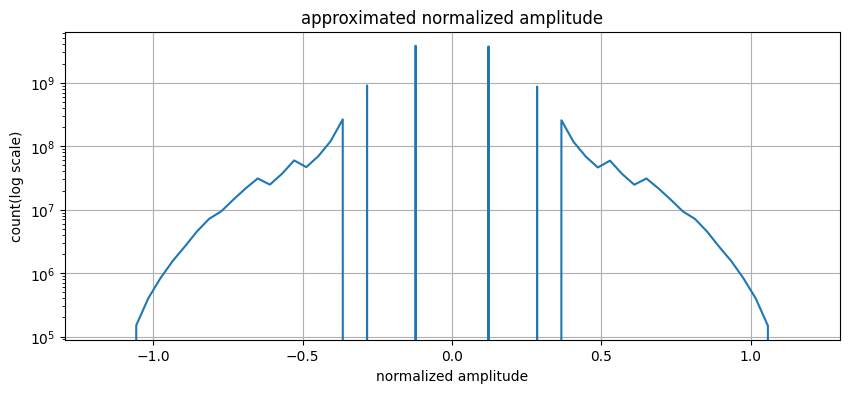

In [22]:
norm_edges=np.linspace(-1.2,1.2,60)
normalized_counts, normalized_edges= np.histogram(normalized_centers, bins= norm_edges, weights= hist_counts)
normalized_intervals_centers = (normalized_edges[:-1] + normalized_edges[1:])/2

plt.figure(figsize=(10,4))
plt.plot(normalized_intervals_centers, normalized_counts)
plt.yscale("log")
plt.title("approximated normalized amplitude")
plt.xlabel("normalized amplitude")
plt.ylabel("count(log scale)")
plt.grid(True)
plt.show()

In [26]:
range = np.random.default_rng(0)
patches_per_file = 100
samples = []
normalized_samples = []
for file in train_files:
    print("now : ", file.name)
    with h5py.File(file,"r") as f:
        patches=f["patches"]
        num_patches = patches.shape[0]
        sample_size = min(patches_per_file, num_patches)
        indexes = range.choice(num_patches, size= sample_size, replace = False)
        indexes = np.sort(indexes)
        patch_batch = patches[indexes]
        x =torch.tensor(patch_batch.reshape(-1))
        y = normalize(x).numpy()
        samples.append(x.numpy())
        normalized_samples.append(y) 

samples = np.concatenate(samples)
normalized_samples = np.concatenate(normalized_samples)

print("number of sampled original values  ", samples.shape[0])
print("original min/max:  ", samples.min(), samples.max())
print("normalized min/max: ", normalized_samples.min(), normalized_samples.max())


now :  train_1000.h5
now :  train_1001.h5
now :  train_1010.h5
now :  train_1011.h5
now :  train_1100.h5
now :  train_1101.h5
now :  train_1110.h5
now :  train_1111.h5
number of sampled original values   104857600
original min/max:   -27628.238 30628.562
normalized min/max:  -1.1298144 1.1464357


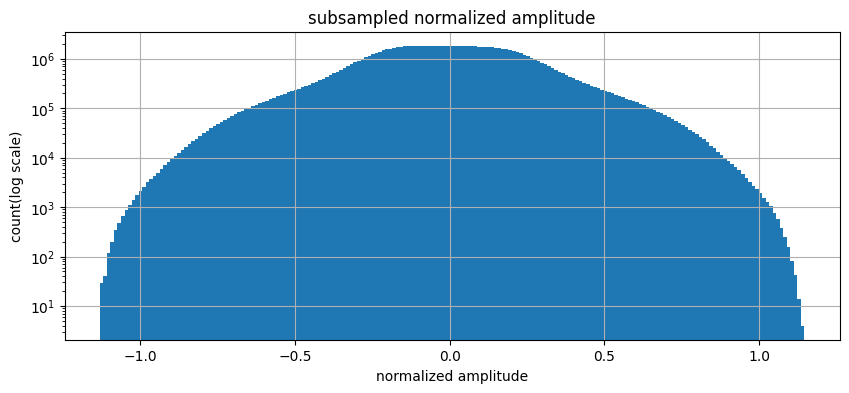

In [27]:
plt.figure(figsize=(10,4))
plt.hist(normalized_samples,bins= 200, log=True)
plt.title("subsampled normalized amplitude")
plt.xlabel("normalized amplitude")
plt.ylabel("count(log scale)")
plt.grid(True)
plt.show()

In [28]:
values = np.percentile(np.abs(samples), percentiles)
for p, v in zip(percentiles, values):
    print(f"|x| percentile {p}% from subsample: {v}")
zero_fraction = np.mean(samples==0)
print("fraction of zero values: ", zero_fraction)    

|x| percentile 50% from subsample: 61.63849639892578
|x| percentile 90% from subsample: 330.3883392333987
|x| percentile 99% from subsample: 2153.812761230478
|x| percentile 99.9% from subsample: 6533.227836425816
|x| percentile 99.99% from subsample: 13645.8701171875
|x| percentile 99.999% from subsample: 20183.632019196957
fraction of zero values:  0.0


In [6]:
top_patches =[]
for file in train_files:
    print("now : ", file.name)
    with h5py.File(file,"r") as f:
        patches=f["patches"]
        num_patches = patches.shape[0]
        for i in range (0, num_patches):
            patch = patches[i]
            max_abs_x = np.max(np.abs(patch))
            top_patches.append((max_abs_x, file.name, i))
top_patches.sort(reverse = True) 
for item in top_patches[:20]:
    max_abs_x, file, patch_index  = item 
    print("|x|: ", max_abs_x, "file: ", file, "patch_index: ", patch_index)    

now :  train_1000.h5
now :  train_1001.h5
now :  train_1010.h5
now :  train_1011.h5
now :  train_1100.h5
now :  train_1101.h5
now :  train_1110.h5
now :  train_1111.h5
|x|:  31438.795 file:  train_1110.h5 patch_index:  3957
|x|:  31402.078 file:  train_1001.h5 patch_index:  8120
|x|:  31402.078 file:  train_1001.h5 patch_index:  2346
|x|:  31402.078 file:  train_1001.h5 patch_index:  2163
|x|:  31402.078 file:  train_1001.h5 patch_index:  1765
|x|:  31402.078 file:  train_1001.h5 patch_index:  1544
|x|:  31053.16 file:  train_1010.h5 patch_index:  6326
|x|:  30852.188 file:  train_1100.h5 patch_index:  5371
|x|:  30795.855 file:  train_1001.h5 patch_index:  14818
|x|:  30791.418 file:  train_1111.h5 patch_index:  3341
|x|:  30791.418 file:  train_1111.h5 patch_index:  2850
|x|:  30791.418 file:  train_1111.h5 patch_index:  1908
|x|:  30791.418 file:  train_1111.h5 patch_index:  294
|x|:  30791.418 file:  train_1011.h5 patch_index:  3663
|x|:  30791.418 file:  train_1011.h5 patch_index:

In [9]:
import json
top_patches_path = "../outputs/DAS_data_analysis/top_patches_x_abs.json"
top = []
for max_abs_x, file, patch_index in top_patches:
    top.append({
        "max_abs_x": float(max_abs_x),
        "file": file,
        "patch_index": patch_index,
    })
with open(top_patches_path, "w") as f:
    json.dump(top,f,indent=4)
print("saved to: ", top_patches_path)        

saved to:  ../outputs/DAS_data_analysis/top_patches_x_abs.json


max|x|:  31438.795


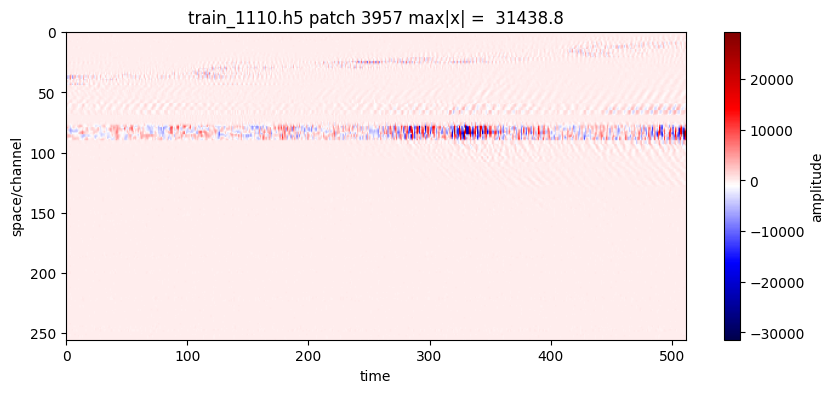

In [17]:
max_abs0, file0, patch_index0 = top_patches[0]
file0_path = das_data/file0
with h5py.File(file0_path,"r") as f:
    patch = f["patches"][patch_index0]
#perc = np.percentile(np.abs(patch), 99.5)
print("max|x|: ", max_abs0)   
plt.figure(figsize=(10,4))
plt.imshow(patch, aspect="auto", cmap="seismic") #vmin=-perc, vmax= perc
plt.colorbar(label="amplitude")
plt.title(f"{file0} patch {patch_index0} max|x| = {max_abs0: .1f}")
plt.xlabel("time")
plt.ylabel("space/channel")
plt.show()

In [25]:
import torch
x0= torch.tensor(patch).float()
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

x0=x0.unsqueeze(0)
x0=x0.to(device)
x0=normalize(x0)

print("x0 shape: ", x0.shape)
print("x0 min/max", x0.min().item(), x0.max().item())

x0 shape:  torch.Size([1, 256, 512])
x0 min/max -1.1506452560424805 1.1396605968475342


In [26]:
from utils.noise_scheduler import LinearNoiseScheduler
scheduler0 = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4, beta_end=0.02, device=device)


-1.1603854894638062 1.142113447189331 0.017925724387168884 0.29166677594184875


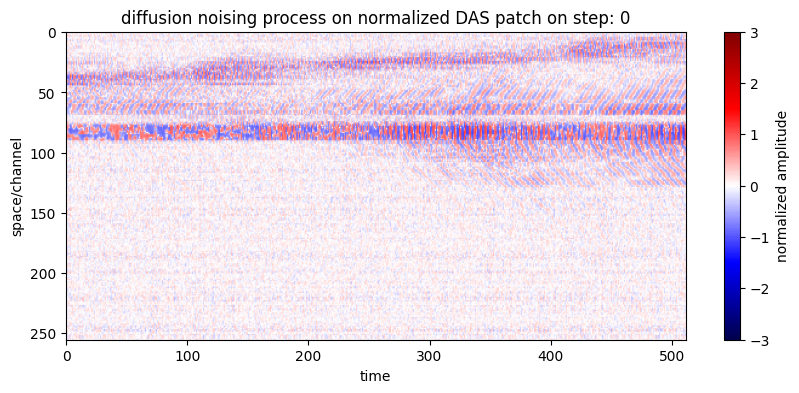

-1.8473107814788818 2.010924816131592 0.01609879918396473 0.42667844891548157


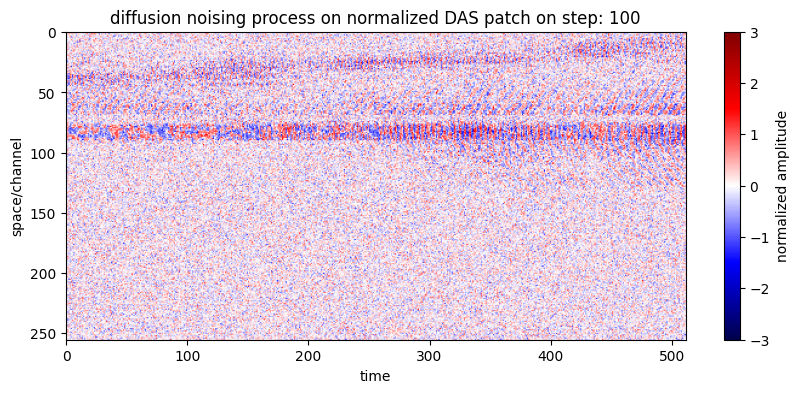

-3.3360767364501953 3.8726022243499756 0.012133938260376453 0.7980162501335144


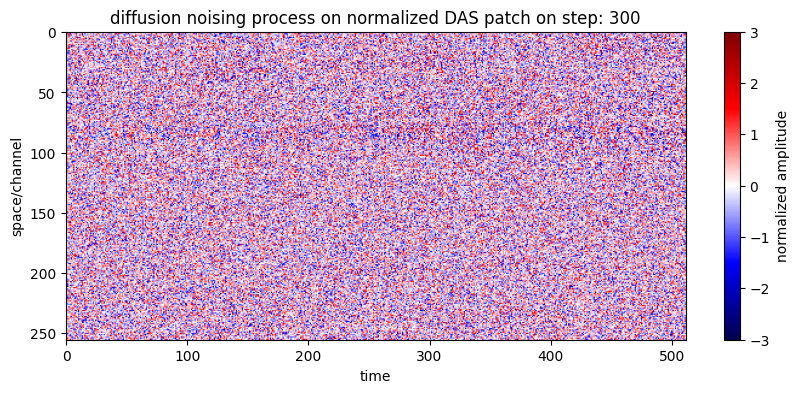

-4.171755790710449 4.451104640960693 0.002934445161372423 0.9648917317390442


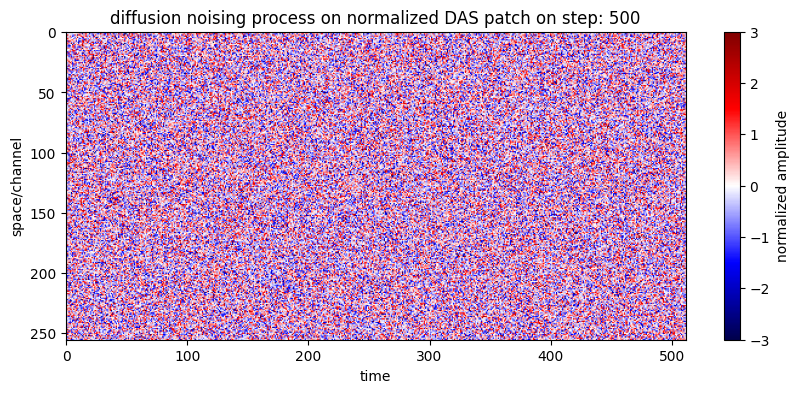

-4.582491397857666 4.792600631713867 0.002587249968200922 1.0036028623580933


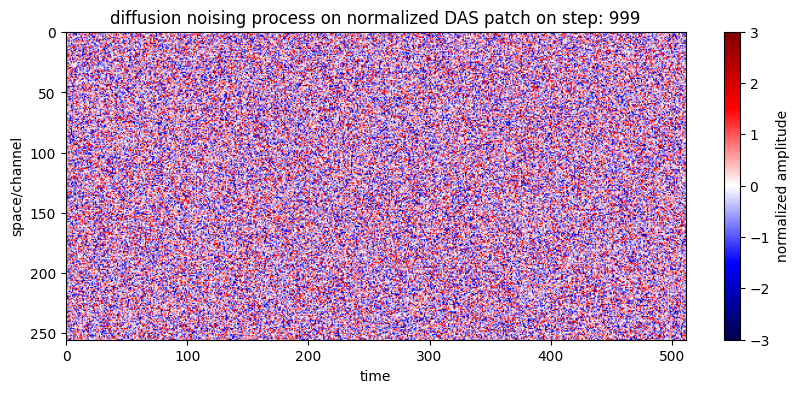

In [31]:
timesteps=[0,100,300,500,999]
for step in timesteps:
    t=torch.tensor([step], device=device)
    epsilon = torch.randn_like(x0)
    x_t= scheduler0.add_noise(x0,epsilon,t)
    image=x_t.squeeze().detach().cpu().numpy()

    print(x_t.min().item(), x_t.max().item(),x_t.mean().item(),x_t.std().item())
    plt.figure(figsize=(10,4))
    plt.imshow(image,aspect="auto",cmap="seismic",vmin=-3,vmax=3)
    plt.colorbar(label="normalized amplitude")
    plt.title(f"diffusion noising process on normalized DAS patch on step: {step}")
    plt.xlabel("time")
    plt.ylabel("space/channel")
    plt.show()

In [33]:
from utils.das_dataset import DasDataset
train_set = DasDataset(train_files)
print("num patches", len(train_set))
patchx = train_set [20]
print("shape ", patchx.shape)
print("min/max: ", patchx.min().item(), patchx.max().item())
print("mean/std: ", patchx.mean().item(), patchx.std().item())

num patches 81920
shape  torch.Size([1, 256, 512])
min/max:  -0.6107227206230164 0.6466777324676514
mean/std:  -0.016094466671347618 0.20910026133060455


In [35]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_set,batch_size=4,shuffle=True)
batch = next(iter(train_loader))
print("batch shape: ", batch.shape)
print("batch min/max: ", batch.min().item(), batch.max().item())

batch shape:  torch.Size([4, 1, 256, 512])
batch min/max:  -1.0600517988204956 1.0569769144058228
